<a href="https://colab.research.google.com/github/OmarLarios/diplomado-tecnicas-estadisticas/blob/main/ejercicios_tareas/02_Ejercicios_VA_discretas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercicios variables aleatorias discretas

**21 de noviembre del 2026**
### Integrantes:
* Humarán González Daniel Zoé
* Flores de la Cruz Mitzel Daniela
* Gonzalez Santos Guadalupe Denisse
* Hernández Larios Omar Emilio

In [1]:
# Importamos las librearias necesarias
import numpy as np
import numpy.random as npr # Para generar números aleatorios
import matplotlib.pyplot as plt # Para graficar
import scipy.stats as sps #Distribuciones de probabilidad
from scipy.stats import bernoulli, binom, poisson, nbinom, geom #Importar cada distribución

## Variable aleatoria Geométrica con parámetro $p\in (0,1)$.

Esta variable aleatoria cuenta el número de fracasos antes del primer éxito en ensayos bernoulli independientes con parámetro $0<p<1$, y su función de masa de probabilidades está dada por:
$$f_{X}(k)=\begin{cases}
	p(1-p)^{k-1} &\quad \text{si } k=1,2,\dots \\
	\qquad 0 &\quad \text{en otro caso}  
\end{cases}$$


Notación. $X\sim Geo(p)$

La cual es una función de densidad ya que:
* $0\le f_{X}(k)\le 1$ para toda $x$.
* $$\begin{align*}
	\sum_{k\in R_{X}}f_{X}(k) &= \sum_{k=1}^{\infty}(1-p)^{k-1}p \\
			&= p\sum_{y=0}^{\infty}(1-p)^{y} \\
			&= p\left(\frac{1}{1-(1-p)}\right) = 1
		\end{align*}$$

Si por el contrario queremos contar el número de éxitos antes del primer fracaso, tenemos que la función de está dada por:
	$$f_{X}(k)=\begin{cases}
		p^{k}(1-p) &\quad \text{si } k=0,1,2,\dots \\
		\qquad 0 &\quad \text{en otro caso}  
	\end{cases}$$

La esperanza de $X$ es:
$$ \mathbb{E}[X]=\frac{1}{p} $$
y
$$\mathbb{E}[X^2]=p\frac{2}{p^3}-\frac{1}{p}=\frac{2}{p^2}-\frac{1}{p}.$$

Por lo tanto,
$$\text{Var}(X)=\frac{2}{p^2}-\frac{1}{p}-\frac{1}{p^2}=\frac{1-p}{p^2}.$$

# Variable Aleatoria Binomial Negativa $X \sim \text{BN}(r, p)$

La distribución **Binomial Negativa** describe procesos donde el número de éxitos está predeterminado ($r$), y nuestra incertidumbre recae sobre cuántos intentos totales ($X$) necesitaremos realizar para alcanzar dicha meta.

Supongamos que se realizan ensayos independientes, cada uno con probabilidad $0<p<1$ de ser un éxito, hasta obtener un total de $r$ éxitos acumulados. Sea $X$ el número de ensayos que se requieren, entonces la probabilidad de que el éxito número $r$ ocurra exactamente en el ensayo $k$ es:

$$f_{X}(k) = \binom{k-1}{r-1} p^r (1-p)^{k-r}$$

Donde:
- El valor de $k$ pertenece al conjunto $\{r, r+1, r+2, \dots\}$.
- El parámetro de Forma ($r$): representa el número de éxitos acumulados que deseamos obtener ($r \geq 1$).
- El parámetro de Intensidad ($p$): es la probabilidad de éxito en cada ensayo independiente ($0 < p < 1$).

El valor promedio esperado de ensayos totales es:
$$\mathbb{E}[X] = \frac{r}{p}$$
 Y la varianza mide la dispersión de los ensayos necesarios:
$$\text{Var}[X] = \frac{r(1-p)}{p^2}$$

$\color{red}{\text{Ejercicio 2.}}$ Un examen de Estadística consta de 20 preguntas tipo test y se conoce de experiencias
anteriores que un alumno tiene probabilidad 0.7 de contestar bien cada pregunta. Obtener:

a) La probabilidad de que la primera pregunta que contesta bien sea la cuarta.

b) Sabiendo que para aprobar el examen es necesario contestar bien a 10 preguntas, ¿cuál es la probabilidad de que apruebe al contestar la pregunta duodécima?

### $\color{blue}{\text{Inciso a)}}$
Como tenemos que sacar la probabilidad de nuestra primer pregunta correcta sea la 4ta, entonces se trata de una distribución geometrica donde $k=4$ que son el total de preguntas contestadas y para la probabilidad de exito tenemos $p=0.7$, con la V.A $X \sim~ Geo(0.7)$

\begin{align*}
f_X(4)= (0.7)(1-0.7)^{4-1}=(0.7)(0.3)^3=0.0189
\end{align*}

### $\color{blue}{\text{Inciso b)}}$

Al ser un ejercicio de tener 10 preguntas correctas y 2 malas, es decir, 10 exitos y 2 fracasos, estamos hablando de una binomial negativa, por lo que para este caso la V.A. $Y \sim BN(10,0.7)$

\begin{align*}
f_Y(2+10)&=f_Y(12)= \binom{12-1}{10-1}(0.7)^{10}(1-0.7)^{12-10} = \binom{11}{9}(0.7)^{10}(0.3)^{2} \\ &=\frac{11!}{([11-9]!)(9!)}(0.0282)(0.09)=\frac{11!}{(2!)(9!)}(0.0282)(0.09) = (55)(0.0025) \\ f_Y(12)&= 0.1395
\end{align*}

In [2]:
#Ejercicio 2
# inciso a)
from scipy.stats import geom, nbinom

#parametros
p = 0.7 #la prob de exito
x = 4 #contestar bien hasta la 4ta pregunta

#solución
sol_a = geom.pmf(x,p)
print(f'La probabilidad de que la primera pregunta que conteste bien sea la 4ta es: {sol_a:.4f}')


#inciso b)
#parametros
r = 10 #los aciertos que queremos sacar
y = 12 - r #el número de fallos que podemos tener

#solución
sol_b = nbinom.pmf(y,r,p)
print(f'La probabilidad de tener 10 preguntas bien al contestar la 12 es: {sol_b:.4f}')

La probabilidad de que la primera pregunta que conteste bien sea la 4ta es: 0.0189
La probabilidad de tener 10 preguntas bien al contestar la 12 es: 0.1398


$\color{red}{\text{Ejercicio 3.}}$ Investigue sobre el problema de la caja de cerillos de Banach y explique su solución (sin simulación).



## Planteamiento

Un matemático (el problema se atribuye a Stefan Banach) lleva una caja de cerillos en cada bolsillo, izquierdo y derecho. Cada caja contiene inicialmente $N$ cerillos. Cada vez que necesita un cerillo, elige una caja al azar, con probabilidad $1/2$ para cada una y de manera independiente.

Un día descubre que la caja que sacó **está vacía**. ¿Cuál es la probabilidad de que la otra caja contenga exactamente $k$ cerillos?

## Solución

**Paso 1. Definir el evento.** Supongamos que la caja **izquierda** es la que se encuentra vacía y que en la derecha quedan $k$ cerillos. Para que esto ocurra:

- La caja izquierda se eligió $N+1$ veces ($N$ cerillos usados y una elección más, cuando se encuentra vacía).
- La caja derecha se eligió $N-k$ veces (se gastaron $N-k$ cerillos y quedan $k$).

En total hubo $(N+1)+(N-k)=2N-k+1$ elecciones.

**Paso 2. Restricción sobre la última elección.** La última elección debe ser la izquierda, pues es la que revela que está vacía. Por tanto, en las primeras $2N-k$ elecciones hay exactamente $N$ izquierdas y $N-k$ derechas, en cualquier orden.

**Paso 3. Probabilidad.** El número de ordenamientos posibles de esas primeras $2N-k$ elecciones es

$$\binom{2N-k}{N}$$

y cada secuencia completa de $2N-k+1$ elecciones tiene probabilidad $\left(\tfrac{1}{2}\right)^{2N-k+1}$. Entonces:

$$P(\text{izquierda vacía, derecha con } k)=\binom{2N-k}{N}\left(\frac{1}{2}\right)^{2N-k+1}$$

**Paso 4. Simetría.** El caso en que la caja **derecha** es la que está vacía es idéntico. Como ambos casos son mutuamente excluyentes, se suman:

$$\boxed{P(k)=2\binom{2N-k}{N}\left(\frac{1}{2}\right)^{2N-k+1}=\binom{2N-k}{N}\left(\frac{1}{2}\right)^{2N-k}},\qquad k=0,1,\dots,N$$

## Verificación

Las probabilidades deben sumar 1:

$$\sum_{k=0}^{N}\binom{2N-k}{N}\left(\frac{1}{2}\right)^{2N-k}=1$$

Ejemplo con $N=1$:

- $k=0$: $\binom{2}{1}\left(\tfrac{1}{2}\right)^2=\tfrac{2}{4}=0.5$
- $k=1$: $\binom{1}{1}\left(\tfrac{1}{2}\right)^1=0.5$

La suma es $1$ ✔.

## Resultado asintótico

Para $N$ grande, el número esperado de cerillos restantes en la otra caja es aproximadamente

$$E[k]\approx 2\sqrt{\frac{N}{\pi}}-1$$

Por ejemplo, con $N=50$ quedan en promedio unos $7$ cerillos. Aunque ambas cajas se eligen con igual probabilidad, al vaciarse una, la otra conserva en promedio un número del orden de $\sqrt{N}$.

## Conclusión

La probabilidad de que, al encontrar una caja vacía, la otra tenga exactamente $k$ cerillos es

$$P(k)=\binom{2N-k}{N}\,2^{-(2N-k)}.$$

La solución se obtiene contando las secuencias válidas de elecciones (distribución binomial), fijando que la última elección es la que revela la caja vacía y duplicando por simetría.

## Variable aleatoria Hipergeométrica con parámetros $n,N,m$.

Supongamos que se elige, **sin reemplazo**, una muestra de tamaño $n$ de una urna que contiene $N$ bolas, de las cuales $m$ son rojas y $N-m$ son verdes. Sea $X$ el número de bolas rojas seleccionadas, entonces su función de masa de probabilidades está dada por:
$$f_{X}(i)=
	\frac{\binom{m}{i}\binom{N-m}{n-i}}{\binom{N}{n}} \quad \text{si } i=0,1,\dots, n  
$$
Donde
- Los valores posibles de $X$ son
$$ i=\max\{0,n-(N-m)\},\dots,\min\{n,m\}. $$

Notación. $X\sim \text{Hiper}(n,N,m)$.

Se tiene que
$$\mathbb{E}[X]=\frac{nm}{N}$$
y
$$\text{Var}[X]=\frac{nm}{N}\left[\frac{(n-1)(m-1)}{N-1}+1-\frac{nm}{N} \right].$$

Equivalentemente,

$$
\mathrm{Var}(X)=n\frac{m}{N}\left(1-\frac{m}{N}\right)\frac{N-n}{N-1}.
$$

**Nota.** Si $i\leq n$ y $X\sim \text{Hiper}(n,N,m)$, con $p=\frac{m}{N}$ y $m,N$ son muy grandes con respecto a $n$ e $i$, entonces
$$\mathbb{P}(X=i)\approx \binom{n}{i}p^{i}(1-p)^{n-i}.$$

Es decir, en poblaciones muy grandes, la distribución hipergeométrica puede aproximarse por una distribución binomial.

$\color{red}{\text{Ejercicio 4.}}$ Ejercio replicar la grafica de la función de densidad

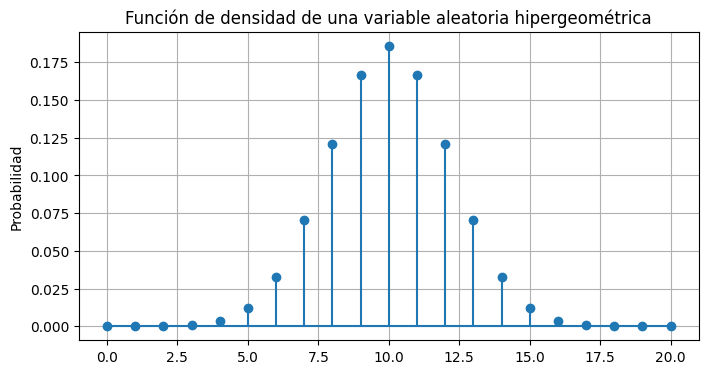

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import hypergeom
#parametros
N = 200 #tamaño total de la muestra
m = 100 #son bolas rojas
n = 20 #tamaño de la muestra que extraemos

x = np.arange(max(0, n - (N-m)), min(n,m) + 1)
pmf_hgeo = hypergeom.pmf(x,N,m,n)

plt.figure(figsize=(8,4))
plt.stem(x,pmf_hgeo, basefmt='')
plt.grid(True)
plt.title("Función de densidad de una variable aleatoria hipergeométrica")
plt.xlabel("")
plt.ylabel("Probabilidad")
plt.show()



$\color{red}{\text{Ejercicio 5.}}$ Una compañía petrolera realiza un estudio geológico que indica que un pozo petrolero exploratorio debería tener un 20% de posibilidades de encontrar petróleo.

- ¿Cuál es la probabilidad de que el primer pozo se produzca en el tercer pozo perforado?

- ¿Cuál es la probabilidad de que el tercer pozo se produzca en el séptimo pozo perforado?

- ¿Cuál es la media y la varianza del número de pozos que se deben perforar si la compañía petrolera quiere establecer tres pozos productores?

$\color{blue}{\text{Solución 5:}}$

Notemos que contamos con los siguientes datos:

Nos dice que la probabilidad de encontrar petroleo en un pozo es $p= 0.20$

* Primer inciso:

Usamos la distribución geometrica ya que buscamos el número de intentos antes del primer éxito. Entonces:  

$$ P ( X = k) = p( 1 - p)^{k-1} $$

$$ \begin{align*}
   \Rightarrow P(X=3) &= (0.20)(1-0.20)^{3-1} \\
    &= (0.20)(0.80)^{2} \\
    &= (0.20)(0.64) \\
    &= 0.128
  \end{align*} $$

In [4]:
# Vamos a calcular la probabilidad de encontrar petroleo en exactamente el tercer pozo perforado

p = 0.2 # Probabilidad de encontrar petroleo en un pozo
k = 3 # Número de intentos (pozos)


inciso1 = geom.pmf(k,p)

print("La probabilidad de encontrar petroleo en exactamente el tercer pozo perforado es:", round(inciso1,3))

La probabilidad de encontrar petroleo en exactamente el tercer pozo perforado es: 0.128


* Segundo inciso:

Usamos la distribución binomial negativa ya que necesitamos que el tercer éxito ocurra exactamente en el séptimo intento.

Esto significa que:
1. En los primeros 6 pozos deben encontrarse exactamente 2 pozos productores.
2. El séptimo pozo necesariamente debe ser productor. Entonces,

$$ P(X=k)=\binom{k-1}{r-1}p^r(1-p)^{k-r} $$

$r=3$ : número de éxitos

$k=7$ : número de intentos

$p = 0.20 $ : probabilidad de éxito



$$ \begin{align*}
   \Rightarrow P(X=7) &=\binom{7-1}{3-1} (0.20)^{3} (1-0.20)^{7-3} \\
    &= \binom{6}{2} (0.20)^{3} (0.80)^{4}\\
    &= (15) (0.008) (0.4096) \\
    &= 0.049152
  \end{align*} $$


In [5]:
# Vamos a calcular la probabilidad de encontrar el tercer éxito en exactamente el séptimo intento

p = 0.2 # Probabilidad de encontrar petroleo en un pozo
r = 3 # Número de éxitos
k = 7 # Número de intentos

inciso1 = nbinom.pmf(k-r,r,p)

print("La probabilidad de encontrar petroleo en exactamente el séptimo pozo perforado es:", round(inciso1,6))

La probabilidad de encontrar petroleo en exactamente el séptimo pozo perforado es: 0.049152


* Tercer inciso:

Seguimos usando la binomial negativa porque queremos alcanzar una cantidad determinada de éxitos. Tenemos:

$r=3$ : número de éxitos

$k=7$ : número de intentos

$p = 0.20 $ : probabilidad de éxito

$$\mathbb{E}(X)=\frac{r}{p}$$

Sustituimos:
$$ \begin{align*}
    \Rightarrow \mathbb{E}(X) &=\frac{3}{0.20}\\
    &=15
  \end{align*}$$

Esto significa que la compañía deberá perforar $15$ pozos para encontrar $3$ con productores. Ahora,

$$ Var(X)=\frac{r(1-p)}{p^2} $$

Sustituimos:
$$ \begin{align*}
    \Rightarrow \mathbb{V}ar(X) &=\frac{3(1-0.20)}{(0.20)^{2}} \\
    &= \frac{3(0.80)}{0.04} \\
    &= \frac{2.4}{0.04} \\
    &= 60
  \end{align*}$$

La varianza es de 60 pozos², lo que significa la dispersión del número de pozos necesarios respecto a su media.

In [6]:
#Calculamos la esperanza y varianza si queremos establecer 3 pozos productores

r=3
p=0.2

media = nbinom.mean(r,p)+r
varianza = nbinom.var(r,p)

print("La media es:", media)
print("La varianza es:", varianza)

La media es: 15.000000000000002
La varianza es: 60.0
